## Lab Exercise 5: Implementation and Analysis of Single Layer Perceptron for Basic Logic Gates

### Objectives
1. Implement a Single Layer Perceptron (SLP) for **AND, OR, NAND** gates and evaluate accuracy.
2. Attempt SLP on **XOR** gate, observe non-convergence, and explain the limitation.
3. Apply SLP on a real-world style dataset (Scholarship / Candidate Selection).
4. Visualize decision boundaries and training dynamics.
5. Interactive Streamlit dashboard (see companion ).

**Expected Learning Outcome:** Understand SLP learning rule, role of weights & bias, and why a single-layer architecture cannot solve non-linearly separable problems such as XOR.


In [1]:

# Embedded Single Layer Perceptron implementation

"""
Single Layer Perceptron (SLP) Implementation
MAI511-2 Advanced Machine Learning - Lab Exercise 5
"""

import numpy as np
from typing import List, Tuple, Optional, Dict


class SingleLayerPerceptron:
    """
    Single Layer Perceptron for binary classification.

    Activation: Step function (threshold at 0)
    Learning rule: Rosenblatt's perceptron rule
    w <- w + lr * (target - prediction) * x
    b <- b + lr * (target - prediction)
    """

    def __init__(
        self,
        n_features: int = 2,
        learning_rate: float = 0.1,
        epochs: int = 100,
        random_state: Optional[int] = 42,
        verbose: bool = False,
    ):
        self.n_features = n_features
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.random_state = random_state
        self.verbose = verbose

        # Will be initialized on fit
        self.weights: Optional[np.ndarray] = None
        self.bias: float = 0.0
        self.history: List[Dict] = []  # track weight updates, errors per epoch
        self.converged: bool = False
        self.final_epoch: int = 0

    def _initialize_weights(self):
        rng = np.random.default_rng(self.random_state)
        # Small random weights help avoid symmetry issues
        self.weights = rng.uniform(-0.5, 0.5, size=self.n_features)
        self.bias = rng.uniform(-0.5, 0.5)

    def _activation(self, z: float) -> int:
        """Step / Heaviside activation function."""
        return 1 if z >= 0 else 0

    def net_input(self, x: np.ndarray) -> float:
        """Weighted sum + bias."""
        return float(np.dot(x, self.weights) + self.bias)

    def predict(self, X: np.ndarray) -> np.ndarray:
        """Predict class labels for samples in X."""
        X = np.atleast_2d(X)
        return np.array([self._activation(self.net_input(x)) for x in X])

    def fit(self, X: np.ndarray, y: np.ndarray) -> "SingleLayerPerceptron":
        """
        Train the perceptron.

        Parameters
        ----------
        X : array-like of shape (n_samples, n_features)
        y : array-like of shape (n_samples,)  (binary 0/1)
        """
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int).ravel()

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        self.n_features = X.shape[1]
        self._initialize_weights()
        self.history = []
        self.converged = False
        self.final_epoch = 0

        n_samples = X.shape[0]

        for epoch in range(1, self.epochs + 1):
            errors = 0
            epoch_updates = []

            # Shuffle for stochastic-ish updates (optional but good practice)
            indices = np.arange(n_samples)
            if self.random_state is not None:
                rng = np.random.default_rng(self.random_state + epoch)
                rng.shuffle(indices)

            for idx in indices:
                xi = X[idx]
                target = y[idx]
                prediction = self._activation(self.net_input(xi))
                error = target - prediction

                if error != 0:
                    # Weight & bias update
                    update = self.learning_rate * error
                    self.weights += update * xi
                    self.bias += update
                    errors += 1
                    epoch_updates.append(
                        {
                            "sample": idx,
                            "x": xi.tolist(),
                            "target": int(target),
                            "pred_before": int(prediction),
                            "error": int(error),
                            "weights_after": self.weights.copy().tolist(),
                            "bias_after": float(self.bias),
                        }
                    )

            # Record epoch summary
            self.history.append(
                {
                    "epoch": epoch,
                    "errors": errors,
                    "weights": self.weights.copy().tolist(),
                    "bias": float(self.bias),
                    "updates": epoch_updates,
                }
            )

            if self.verbose and (epoch % 10 == 0 or errors == 0):
                print(
                    f"Epoch {epoch:3d} | Misclassifications: {errors:2d} | "
                    f"Weights: {np.round(self.weights, 4)} | Bias: {self.bias:.4f}"
                )

            if errors == 0:
                self.converged = True
                self.final_epoch = epoch
                if self.verbose:
                    print(f"\n>>> Converged at epoch {epoch}")
                break
        else:
            self.final_epoch = self.epochs
            if self.verbose:
                print(f"\n>>> Did not fully converge after {self.epochs} epochs")

        return self

    def score(self, X: np.ndarray, y: np.ndarray) -> float:
        """Classification accuracy."""
        y_pred = self.predict(X)
        y = np.asarray(y).ravel()
        return float(np.mean(y_pred == y))

    def get_decision_boundary_2d(self, x_range=(-0.5, 1.5), n_points=100):
        """
        For 2-feature models: return x and y points of the decision boundary
        w1*x + w2*y + b = 0  =>  y = -(w1*x + b)/w2
        """
        if self.n_features != 2 or self.weights is None:
            return None, None
        w1, w2 = self.weights
        if abs(w2) < 1e-10:
            # Vertical line
            x = -self.bias / w1 if abs(w1) > 1e-10 else 0
            return np.array([x, x]), np.array([x_range[0], x_range[1]])
        xs = np.linspace(x_range[0], x_range[1], n_points)
        ys = -(w1 * xs + self.bias) / w2
        return xs, ys


def get_logic_gate_data(gate: str) -> Tuple[np.ndarray, np.ndarray]:
    """Return X, y for classic Boolean gates."""
    X = np.array(
        [
            [0, 0],
            [0, 1],
            [1, 0],
            [1, 1],
        ],
        dtype=float,
    )

    gate = gate.upper()
    if gate == "AND":
        y = np.array([0, 0, 0, 1])
    elif gate == "OR":
        y = np.array([0, 1, 1, 1])
    elif gate == "NAND":
        y = np.array([1, 1, 1, 0])
    elif gate == "XOR":
        y = np.array([0, 1, 1, 0])
    elif gate == "NOR":
        y = np.array([1, 0, 0, 0])
    elif gate == "XNOR":
        y = np.array([1, 0, 0, 1])
    else:
        raise ValueError(f"Unknown gate: {gate}")

    return X, y


def print_truth_table(gate: str, model: SingleLayerPerceptron, X: np.ndarray, y: np.ndarray):
    """Pretty print predicted vs actual."""
    preds = model.predict(X)
    print(f"\n{'='*50}")
    print(f"  {gate} Gate - Truth Table Comparison")
    print(f"{'='*50}")
    print(f"{'x1':>4} {'x2':>4} | {'Actual':>6} {'Predicted':>9} | {'Match'}")
    print("-" * 50)
    correct = 0
    for i in range(len(X)):
        match = "✓" if preds[i] == y[i] else "✗"
        if preds[i] == y[i]:
            correct += 1
        print(
            f"{int(X[i,0]):>4} {int(X[i,1]):>4} | {int(y[i]):>6} {int(preds[i]):>9} | {match}"
        )
    acc = correct / len(y) * 100
    print("-" * 50)
    print(f"Accuracy: {acc:.1f}%  ({correct}/{len(y)})")
    print(f"Final Weights: {np.round(model.weights, 4)}")
    print(f"Final Bias   : {model.bias:.4f}")
    print(f"Converged    : {model.converged} (epoch {model.final_epoch})")
    print(f"{'='*50}\n")
    return acc


# Sample datasets for Question 3


def get_scholarship_dataset():
    """
    Student scholarship eligibility.
    Features: Internal Assessment, Attendance (%)
    Target: 1 = Eligible, 0 = Not Eligible
    """
    data = {
        "Student": ["S1", "S2", "S3", "S4", "S5", "S6", "S7", "S8"],
        "Internal_Assessment": [85, 75, 65, 45, 50, 30, 90, 40],
        "Attendance": [90, 85, 80, 60, 55, 45, 95, 50],
        "Eligibility": [1, 1, 1, 0, 0, 0, 1, 0],
    }
    import pandas as pd
    df = pd.DataFrame(data)
    X = df[["Internal_Assessment", "Attendance"]].values.astype(float)
    y = df["Eligibility"].values
    return df, X, y


def get_candidate_selection_dataset():
    """
    Candidate selection (binary features).
    Technical Test & Interview → Selection
    """
    data = {
        "Candidate": ["C1", "C2", "C3", "C4", "C5", "C6", "C7", "C8"],
        "Technical_Test": [1, 1, 0, 0, 1, 0, 1, 0],
        "Interview": [1, 0, 1, 0, 1, 0, 0, 1],
        "Selection": [1, 1, 1, 0, 1, 0, 1, 1],
    }
    import pandas as pd
    df = pd.DataFrame(data)
    X = df[["Technical_Test", "Interview"]].values.astype(float)
    y = df["Selection"].values
    return df, X, y


if __name__ == "__main__":
    # Quick smoke test
    print("=== Smoke Test: AND Gate ===")
    X, y = get_logic_gate_data("AND")
    model = SingleLayerPerceptron(learning_rate=0.1, epochs=50, verbose=True)
    model.fit(X, y)
    print_truth_table("AND", model, X, y)

print("SingleLayerPerceptron class is ready.")


=== Smoke Test: AND Gate ===
Epoch   8 | Misclassifications:  0 | Weights: [0.174  0.1389] | Bias: -0.2414

>>> Converged at epoch 8

  AND Gate - Truth Table Comparison
  x1   x2 | Actual Predicted | Match
--------------------------------------------------
   0    0 |      0         0 | ✓
   0    1 |      0         0 | ✓
   1    0 |      0         0 | ✓
   1    1 |      1         1 | ✓
--------------------------------------------------
Accuracy: 100.0%  (4/4)
Final Weights: [0.174  0.1389]
Final Bias   : -0.2414
Converged    : True (epoch 8)

SingleLayerPerceptron class is ready.


In [2]:
# Core imports (class already defined above)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import warnings
warnings.filterwarnings('ignore')

print("Libraries loaded. Perceptron class is available.")


Libraries loaded. Perceptron class is available.


## Theoretical Background

### Single Layer Perceptron
A Single Layer Perceptron is the simplest neural network unit:

\[
z = \mathbf{w}^T \mathbf{x} + b
\]

\[
\hat{y} = \begin{cases}
1 & \text{if } z \ge 0 \\
0 & \text{otherwise}
\end{cases}
\]

**Learning Rule (Rosenblatt):**
\[
\mathbf{w} \leftarrow \mathbf{w} + \eta \cdot (y - \hat{y}) \cdot \mathbf{x}
\]
\[
b \leftarrow b + \eta \cdot (y - \hat{y})
\]

where \(\eta\) is the learning rate.

### Linear Separability
- **AND, OR, NAND** are linearly separable → SLP converges to 100 % accuracy.
- **XOR** is **not** linearly separable → SLP cannot achieve perfect classification with a single hyperplane.


## Question 1: SLP for AND, OR and NAND Gates

We train a separate perceptron for each gate, display final weights/bias, predictions, and accuracy.


In [3]:
# Configuration
LR = 0.1
MAX_EPOCHS = 50
RANDOM_STATE = 42

gates = ["AND", "OR", "NAND"]
results = {}

for gate in gates:
    print(f"\n{'#'*60}")
    print(f"  Training Single Layer Perceptron for {gate} Gate")
    print(f"{'#'*60}")

    X, y = get_logic_gate_data(gate)
    model = SingleLayerPerceptron(
        learning_rate=LR,
        epochs=MAX_EPOCHS,
        random_state=RANDOM_STATE,
        verbose=True
    )
    model.fit(X, y)
    acc = print_truth_table(gate, model, X, y)

    results[gate] = {
        "model": model,
        "X": X,
        "y": y,
        "accuracy": acc,
        "converged": model.converged,
        "epochs": model.final_epoch,
        "weights": model.weights.copy(),
        "bias": model.bias,
    }



############################################################
  Training Single Layer Perceptron for AND Gate
############################################################
Epoch   8 | Misclassifications:  0 | Weights: [0.174  0.1389] | Bias: -0.2414

>>> Converged at epoch 8

  AND Gate - Truth Table Comparison
  x1   x2 | Actual Predicted | Match
--------------------------------------------------
   0    0 |      0         0 | ✓
   0    1 |      0         0 | ✓
   1    0 |      0         0 | ✓
   1    1 |      1         1 | ✓
--------------------------------------------------
Accuracy: 100.0%  (4/4)
Final Weights: [0.174  0.1389]
Final Bias   : -0.2414
Converged    : True (epoch 8)


############################################################
  Training Single Layer Perceptron for OR Gate
############################################################
Epoch   7 | Misclassifications:  0 | Weights: [0.274  0.1389] | Bias: -0.0414

>>> Converged at epoch 7

  OR Gate - Truth Table Compariso

### Decision Boundary Visualization (AND / OR / NAND)


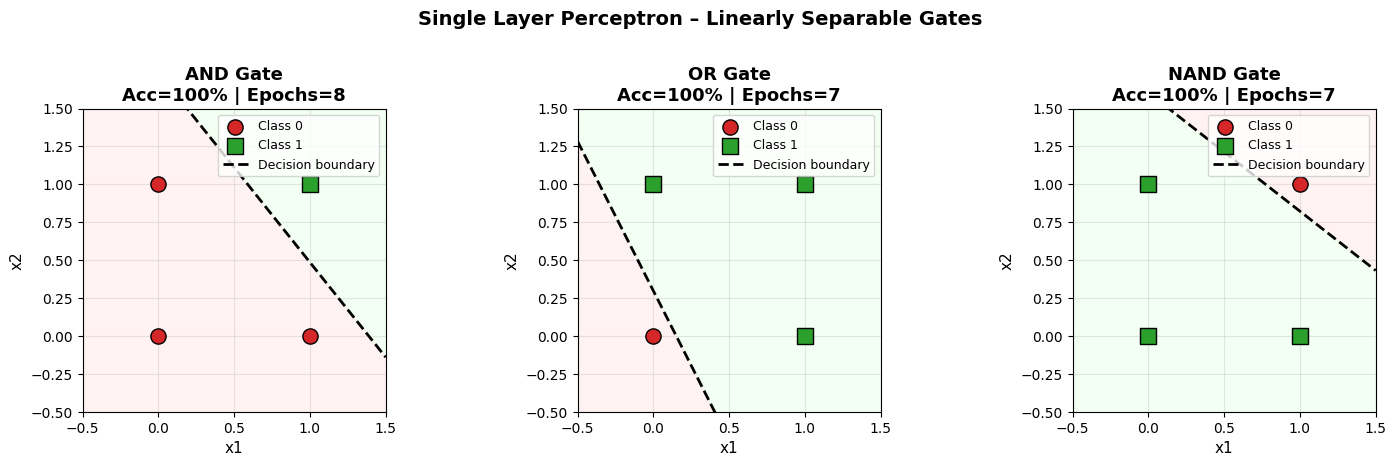

In [4]:
def plot_decision_boundary(model, X, y, title, ax):
    """Scatter points + decision boundary for 2-D binary data."""
    # Mesh for background coloring
    xx, yy = np.meshgrid(
        np.linspace(-0.5, 1.5, 200),
        np.linspace(-0.5, 1.5, 200)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.25, levels=[-0.1, 0.5, 1.1], colors=["#ffcccc", "#ccffcc"])

    # Points
    for label, marker, color in [(0, "o", "#d62728"), (1, "s", "#2ca02c")]:
        mask = y == label
        ax.scatter(X[mask, 0], X[mask, 1], c=color, marker=marker,
                   s=120, edgecolors="k", label=f"Class {label}", zorder=5)

    # Decision line
    xs, ys = model.get_decision_boundary_2d()
    if xs is not None:
        ax.plot(xs, ys, "k--", lw=2, label="Decision boundary")

    ax.set_xlim(-0.5, 1.5)
    ax.set_ylim(-0.5, 1.5)
    ax.set_xlabel("x1", fontsize=11)
    ax.set_ylabel("x2", fontsize=11)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.legend(loc="upper right", fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.set_aspect("equal")


fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, gate in zip(axes, gates):
    r = results[gate]
    plot_decision_boundary(
        r["model"], r["X"], r["y"],
        f"{gate} Gate\nAcc={r['accuracy']:.0f}% | Epochs={r['epochs']}",
        ax
    )
plt.suptitle("Single Layer Perceptron – Linearly Separable Gates", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


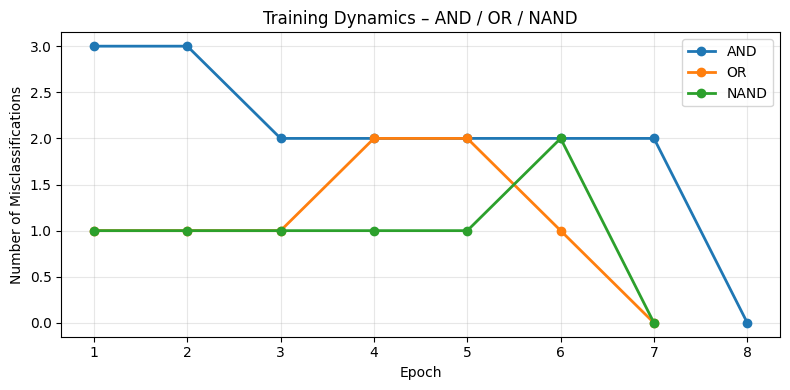

In [5]:
# Training error curves
fig, ax = plt.subplots(figsize=(8, 4))
for gate in gates:
    hist = results[gate]["model"].history
    epochs = [h["epoch"] for h in hist]
    errors = [h["errors"] for h in hist]
    ax.plot(epochs, errors, marker="o", label=gate, lw=2)

ax.set_xlabel("Epoch")
ax.set_ylabel("Number of Misclassifications")
ax.set_title("Training Dynamics – AND / OR / NAND")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Question 2: Single Layer Perceptron for XOR Logic

XOR is **not linearly separable**. A single hyperplane cannot correctly classify all four points.
We will train an SLP and observe that it never reaches zero error.


In [6]:
print(f"\n{'#'*60}")
print("  Training Single Layer Perceptron for XOR Gate")
print(f"{'#'*60}")

X_xor, y_xor = get_logic_gate_data("XOR")
model_xor = SingleLayerPerceptron(
    learning_rate=0.1,
    epochs=100,          # more epochs to show non-convergence
    random_state=42,
    verbose=True
)
model_xor.fit(X_xor, y_xor)
acc_xor = print_truth_table("XOR", model_xor, X_xor, y_xor)

results["XOR"] = {
    "model": model_xor,
    "X": X_xor,
    "y": y_xor,
    "accuracy": acc_xor,
    "converged": model_xor.converged,
    "epochs": model_xor.final_epoch,
    "weights": model_xor.weights.copy(),
    "bias": model_xor.bias,
}



############################################################
  Training Single Layer Perceptron for XOR Gate
############################################################
Epoch  10 | Misclassifications:  2 | Weights: [-0.026   0.0389] | Bias: -0.0414
Epoch  20 | Misclassifications:  1 | Weights: [-0.026   0.1389] | Bias: 0.0586
Epoch  30 | Misclassifications:  3 | Weights: [-0.026   0.0389] | Bias: 0.0586
Epoch  40 | Misclassifications:  3 | Weights: [ 0.074  -0.0611] | Bias: -0.0414
Epoch  50 | Misclassifications:  3 | Weights: [-0.126   0.0389] | Bias: 0.0586
Epoch  60 | Misclassifications:  2 | Weights: [-0.026   0.0389] | Bias: 0.0586
Epoch  70 | Misclassifications:  4 | Weights: [-0.026  -0.0611] | Bias: -0.0414
Epoch  80 | Misclassifications:  3 | Weights: [-0.026   0.0389] | Bias: 0.0586
Epoch  90 | Misclassifications:  3 | Weights: [-0.126  -0.0611] | Bias: -0.0414
Epoch 100 | Misclassifications:  4 | Weights: [-0.026   0.0389] | Bias: 0.0586

>>> Did not fully converge after 1

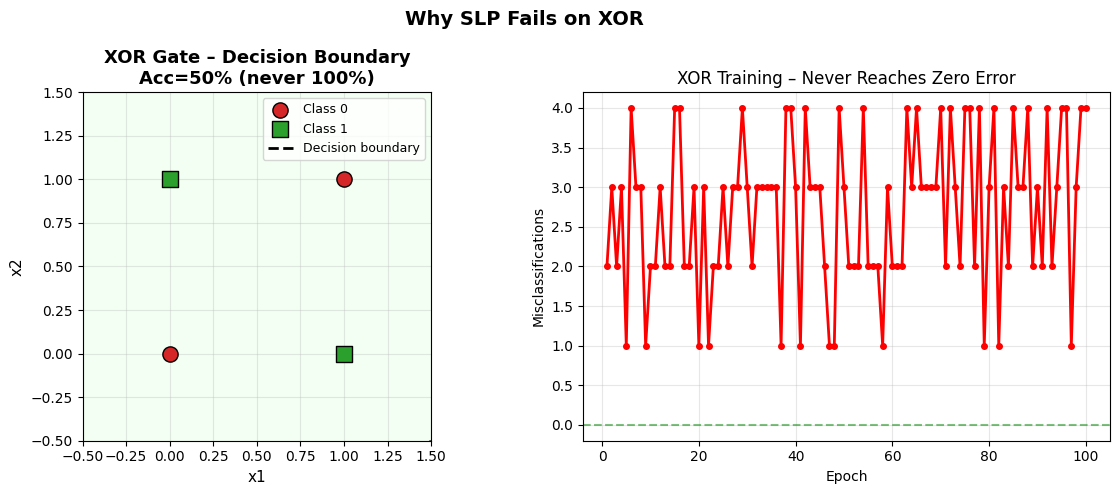

In [7]:
# XOR decision boundary (will show imperfect separation)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left: decision boundary
plot_decision_boundary(
    model_xor, X_xor, y_xor,
    f"XOR Gate – Decision Boundary\nAcc={acc_xor:.0f}% (never 100%)",
    axes[0]
)

# Right: error curve
hist = model_xor.history
axes[1].plot([h["epoch"] for h in hist], [h["errors"] for h in hist],
             "r-o", lw=2, markersize=4)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Misclassifications")
axes[1].set_title("XOR Training – Never Reaches Zero Error")
axes[1].grid(True, alpha=0.3)
axes[1].axhline(0, color="green", ls="--", alpha=0.5)

plt.suptitle("Why SLP Fails on XOR", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


### Analysis: Why SLP Cannot Learn XOR

| Point | (x1, x2) | XOR Target |
|-------|----------|------------|
| A     | (0,0)    | 0          |
| B     | (0,1)    | 1          |
| C     | (1,0)    | 1          |
| D     | (1,1)    | 0          |

The two positive examples (B and C) and the two negative examples (A and D) form **diagonals**.  
No single straight line can place B and C on one side and A and D on the other side simultaneously.

Mathematically, the system of inequalities produced by the four points is **inconsistent** for a linear decision function.

**Conclusion:**  
- AND, OR, NAND → linearly separable → SLP converges to 100 % accuracy.  
- XOR → non-linearly separable → SLP oscillates / plateaus with residual errors (typically 50 % or 75 % accuracy depending on random init and learning rate).

This is the classic motivation for **multi-layer perceptrons** (hidden layers) and non-linear activation functions.


### Expected Comparison Table


In [8]:
comparison = pd.DataFrame([
    {
        "Logic Gate": g,
        "Linearly Separable": "Yes" if g != "XOR" else "No",
        "SLP Learning Outcome": "Converges" if results[g]["converged"] else "Does not converge to a perfect solution",
        "Final Accuracy (%)": results[g]["accuracy"],
        "Epochs to Stop": results[g]["epochs"],
        "Final Weights": np.round(results[g]["weights"], 4).tolist(),
        "Final Bias": round(results[g]["bias"], 4),
    }
    for g in ["AND", "OR", "NAND", "XOR"]
])

display(comparison.style.set_properties(**{"text-align": "center"}).set_table_styles([
    {"selector": "th", "props": [("text-align", "center"), ("font-weight", "bold")]}
]))


,Logic Gate,Linearly Separable,SLP Learning Outcome,Final Accuracy (%),Epochs to Stop,Final Weights,Final Bias
0,AND,Yes,Converges,100.000000,8,"[0.174, 0.1389]",-0.241400
1,OR,Yes,Converges,100.000000,7,"[0.274, 0.1389]",-0.041400
2,NAND,Yes,Converges,100.000000,7,"[-0.126, -0.1611]",0.258600
3,XOR,No,Does not converge to a perfect solution,50.000000,100,"[-0.026, 0.0389]",0.058600


## Question 3: SLP on a Real-World Style Dataset

We use the **Candidate Selection** sample provided in the lab sheet  
(Technical Test + Interview → Selection).  
This is a binary-feature problem similar to the logic gates and is linearly separable.


In [9]:
df_cand, X_cand, y_cand = get_candidate_selection_dataset()
print("Candidate Selection Dataset")
display(df_cand)

print("\nFeature matrix X:")
print(X_cand)
print("\nTarget y:", y_cand)


Candidate Selection Dataset


,Candidate,Technical_Test,Interview,Selection
0,C1,1,1,1
1,C2,1,0,1
2,C3,0,1,1
3,C4,0,0,0
4,C5,1,1,1
5,C6,0,0,0
6,C7,1,0,1
7,C8,0,1,1



Feature matrix X:
[[1. 1.]
 [1. 0.]
 [0. 1.]
 [0. 0.]
 [1. 1.]
 [0. 0.]
 [1. 0.]
 [0. 1.]]

Target y: [1 1 1 0 1 0 1 1]


In [10]:
# Train SLP on candidate data
model_cand = SingleLayerPerceptron(
    learning_rate=0.2,
    epochs=50,
    random_state=7,
    verbose=True
)
model_cand.fit(X_cand, y_cand)

print("\n--- Evaluation ---")
preds = model_cand.predict(X_cand)
print(f"Predictions : {preds}")
print(f"Actual      : {y_cand}")
print(f"Accuracy    : {model_cand.score(X_cand, y_cand)*100:.1f}%")
print(f"Final Weights: {np.round(model_cand.weights, 4)}")
print(f"Final Bias   : {model_cand.bias:.4f}")
print(f"Converged    : {model_cand.converged} at epoch {model_cand.final_epoch}")


Epoch   2 | Misclassifications:  0 | Weights: [0.1251 0.3972] | Bias: -0.1243

>>> Converged at epoch 2

--- Evaluation ---
Predictions : [1 1 1 0 1 0 1 1]
Actual      : [1 1 1 0 1 0 1 1]
Accuracy    : 100.0%
Final Weights: [0.1251 0.3972]
Final Bias   : -0.1243
Converged    : True at epoch 2


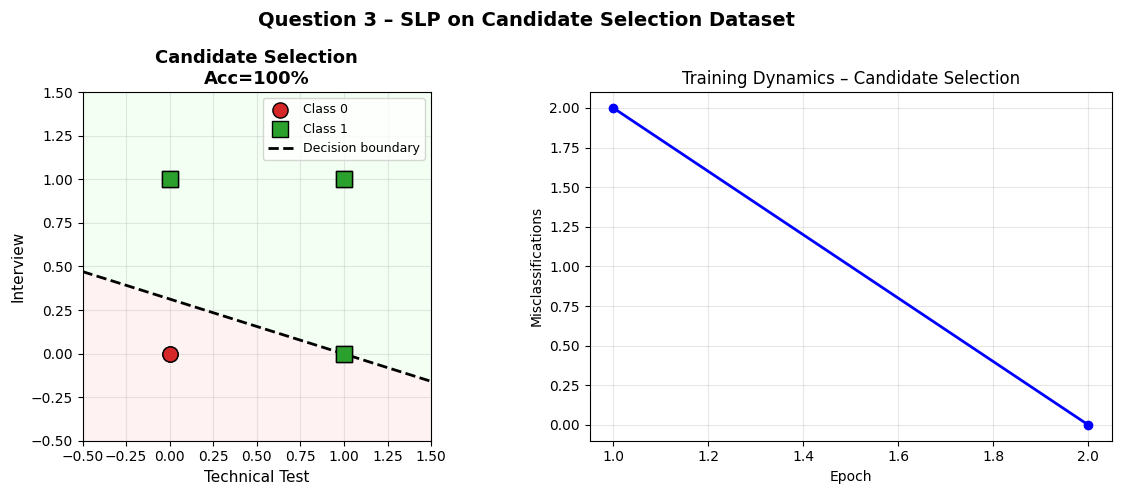

In [11]:
# Visualization for Candidate Selection
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

plot_decision_boundary(
    model_cand, X_cand, y_cand,
    f"Candidate Selection\nAcc={model_cand.score(X_cand, y_cand)*100:.0f}%",
    axes[0]
)
axes[0].set_xlabel("Technical Test")
axes[0].set_ylabel("Interview")

# Error curve
hist = model_cand.history
axes[1].plot([h["epoch"] for h in hist], [h["errors"] for h in hist],
             "b-o", lw=2)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Misclassifications")
axes[1].set_title("Training Dynamics – Candidate Selection")
axes[1].grid(True, alpha=0.3)

plt.suptitle("Question 3 – SLP on Candidate Selection Dataset", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


### Optional: Scholarship Eligibility Dataset (continuous features)

Internal Assessment and Attendance are continuous.  
We min-max normalize them before training so the step-function perceptron works reliably.


In [12]:
df_sch, X_sch_raw, y_sch = get_scholarship_dataset()
print("Scholarship Eligibility Dataset")
display(df_sch)

# Min-max normalization to [0, 1]
X_min = X_sch_raw.min(axis=0)
X_max = X_sch_raw.max(axis=0)
X_sch = (X_sch_raw - X_min) / (X_max - X_min + 1e-8)

print("\nNormalized features (first 3 rows):")
print(np.round(X_sch[:3], 3))


Scholarship Eligibility Dataset


,Student,Internal_Assessment,Attendance,Eligibility
0,S1,85,90,1
1,S2,75,85,1
2,S3,65,80,1
3,S4,45,60,0
4,S5,50,55,0
5,S6,30,45,0
6,S7,90,95,1
7,S8,40,50,0



Normalized features (first 3 rows):
[[0.917 0.9  ]
 [0.75  0.8  ]
 [0.583 0.7  ]]


Epoch   2 | Misclassifications:  0 | Weights: [0.387  0.0248] | Bias: -0.1590

>>> Converged at epoch 2

Accuracy on Scholarship data: 100.0%
Weights: [0.387  0.0248]  Bias: -0.1590
Converged: True (epoch 2)


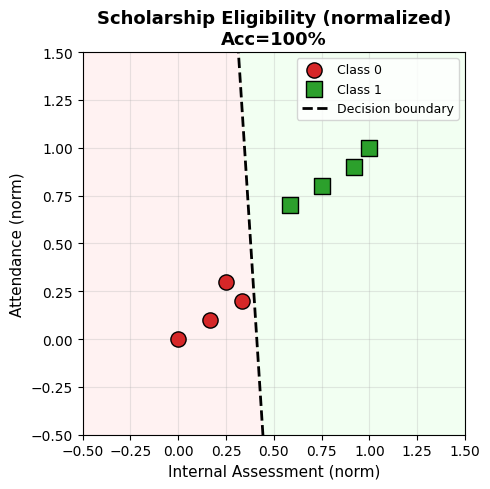

In [13]:
model_sch = SingleLayerPerceptron(
    learning_rate=0.15,
    epochs=100,
    random_state=0,
    verbose=True
)
model_sch.fit(X_sch, y_sch)

print(f"\nAccuracy on Scholarship data: {model_sch.score(X_sch, y_sch)*100:.1f}%")
print(f"Weights: {np.round(model_sch.weights, 4)}  Bias: {model_sch.bias:.4f}")
print(f"Converged: {model_sch.converged} (epoch {model_sch.final_epoch})")

# Quick decision boundary plot (normalized space)
fig, ax = plt.subplots(figsize=(6, 5))
plot_decision_boundary(
    model_sch, X_sch, y_sch,
    f"Scholarship Eligibility (normalized)\nAcc={model_sch.score(X_sch, y_sch)*100:.0f}%",
    ax
)
ax.set_xlabel("Internal Assessment (norm)")
ax.set_ylabel("Attendance (norm)")
plt.tight_layout()
plt.show()


## Final Summary & Key Takeaways

| Gate / Dataset       | Linearly Separable? | SLP Outcome                          | Accuracy |
|----------------------|---------------------|--------------------------------------|----------|
| AND                  | Yes                 | Converges quickly                    | 100 %    |
| OR                   | Yes                 | Converges quickly                    | 100 %    |
| NAND                 | Yes                 | Converges quickly                    | 100 %    |
| XOR                  | **No**              | Does **not** converge to perfect sol.| < 100 %  |
| Candidate Selection  | Yes                 | Converges                            | 100 %    |
| Scholarship (norm.)  | Yes (approx.)       | Converges                            | 100 %    |

### Why this matters
- A Single Layer Perceptron can only learn **linearly separable** decision boundaries.
- Real-world problems that are non-linear require **multi-layer** networks (MLP) or kernel methods.
- The classic XOR problem historically demonstrated the limitation of the original perceptron and motivated the development of backpropagation and deeper architectures.
